In [9]:
import os
import pandas as pd
import numpy as np 
from pathlib import Path
from dotenv import dotenv_values
from sqlalchemy import create_engine

# Load credentials from .env in the current file directory or root
env_file = Path('.env') if Path('.env').is_file() else Path('Python/.env')
config = (
    dotenv_values(env_file, encoding='utf-8-sig')
    if env_file.is_file()
    else os.environ
)

DB_USER = config.get('DB_USER', 'postgres')
DB_PASS = config.get('DB_PASS', '')
DB_HOST = config.get('DB_HOST', 'localhost')
DB_PORT = config.get('DB_PORT', '5432')
DB_NAME = config.get('DB_NAME', 'Olist_Customer_DataBase')

engine = create_engine(
    f'postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}'
)
# Loading the Dataset

query = """
SELECT 
    o.order_id,
    o.order_status,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_unique_id,
    c.customer_state,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    COALESCE(t.product_category_name_english, p.product_category_name) AS product_category,
    r.review_score
FROM orders o
JOIN customer_dataset c ON o.customer_id = c.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
LEFT JOIN products p ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
LEFT JOIN order_review r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered';
"""
df = pd.read_sql(query, con=engine)

# Checking the Size and the Null Values 

print("Shape", df.shape)
print("\n-----Null Values-----")
print(df.isnull().sum())






Shape (110840, 14)

-----Null Values-----
order_id                            0
order_status                        0
order_purchase_timestamp            0
order_delivered_customer_date       8
order_estimated_delivery_date       0
customer_unique_id                  0
customer_state                      0
order_item_id                       0
product_id                          0
seller_id                           0
price                               0
freight_value                       0
product_category                 1545
review_score                      827
dtype: int64


In [10]:
# Cleaning the 8 Missing Delivery_Customer_Date and Imputing the Product_category
df_clean = df.dropna(subset=['order_delivered_customer_date']).copy()
df_clean['product_category'] = df_clean['product_category'].fillna('unknown')

# Timestamp Parsing

date_columns = ['order_purchase_timestamp',
                'order_delivered_customer_date',
                'order_estimated_delivery_date']
for col in date_columns:
    df_clean[col]=pd.to_datetime(df_clean[col])

df_clean['delivery_days'] = (
    df_clean['order_delivered_customer_date'] - df_clean['order_purchase_timestamp']
).dt.total_seconds()/86400.0



df_clean['estimated_days'] = (
    df_clean['order_estimated_delivery_date'] - df_clean['order_purchase_timestamp']).dt.total_seconds()/86400.0

df_clean['delay_days'] = (
    df_clean['order_delivered_customer_date']-df_clean['order_estimated_delivery_date']).dt.total_seconds()/86400.0



        
df_clean['is_late'] = (df_clean['delay_days']>0).astype(int)

print(df_clean[['delivery_days','estimated_days','delay_days','is_late']].describe().round(2))



       delivery_days  estimated_days  delay_days    is_late
count      110832.00       110832.00   110832.00  110832.00
mean           12.48           23.81      -11.34       0.08
std             9.44            8.82       10.16       0.27
min             0.53            2.01     -146.02       0.00
25%             6.74           18.37      -16.32       0.00
50%            10.19           23.25      -12.05       0.00
75%            15.56           28.46       -6.48       0.00
max           209.63          155.14      188.98       1.00


In [11]:
# Calculate Q1, Q3 and IQR for price and freight_value

Q1_price = df_clean['price'].quantile(0.25)
Q3_price = df_clean['price'].quantile(0.75)
IQR_price = Q3_price - Q1_price

upper_bound_price = Q3_price + 1.5*IQR_price

Q1_freight_value = df_clean['freight_value'].quantile(0.25)
Q3_freight_value = df_clean['freight_value'].quantile(0.75)
IQR_freight_value = Q3_freight_value - Q1_freight_value

upper_bound_freight_value = Q3_freight_value + 1.5*IQR_freight_value

price_outliers = (df_clean['price']>upper_bound_price).sum()
freight_value_outliers = (df_clean['freight_value']>upper_bound_freight_value).sum()


print(f'Q1 Price = {Q1_price:.2f} , Q3 price = {Q3_price:.2f}, IQR = {IQR_price:.2f}, Upper Threshold = {upper_bound_price:.2f}')
print(f'Price Outliers Count : {price_outliers} ({price_outliers / len(df_clean) *100:.2f}%)')
print(f'Q1 Freight Value = {Q1_freight_value:.2f} , Q3 Freight Value = {Q3_freight_value:.2f}, IQR = {IQR_freight_value:.2f}, Upper Threshold = {upper_bound_freight_value:.2f}')
print(f'Freight Value Outliers Count : {freight_value_outliers} ({freight_value_outliers/len(df_clean) *100:.2f}%)')



Q1 Price = 39.90 , Q3 price = 133.90, IQR = 94.00, Upper Threshold = 274.90
Price Outliers Count : 8217 (7.41%)
Q1 Freight Value = 13.08 , Q3 Freight Value = 21.15, IQR = 8.07, Upper Threshold = 33.25
Freight Value Outliers Count : 11338 (10.23%)


In [12]:
# Correrlation between the numericals in the Dataset


review_df = df_clean.dropna(subset=['review_score']).copy()

num_columns = ['delivery_days','delay_days','price','freight_value','review_score']
pearson_corr = review_df[num_columns].corr(method = 'pearson')['review_score']
spearman_corr = review_df[num_columns].corr(method='spearman')['review_score']
print('Pearson Correleation : ')
print(pearson_corr)
print("Spearman Correleation : ")
print(spearman_corr)

grouped = review_df.groupby('is_late')['review_score'].agg(['count','median','mean'])
print(grouped.round(2))

Pearson Correleation : 
delivery_days   -0.304055
delay_days      -0.228907
price            0.003263
freight_value   -0.032895
review_score     1.000000
Name: review_score, dtype: float64
Spearman Correleation : 
delivery_days   -0.220818
delay_days      -0.151986
price            0.009917
freight_value   -0.046062
review_score     1.000000
Name: review_score, dtype: float64
          count  median  mean
is_late                      
0        101445     5.0  4.21
1          8560     2.0  2.55


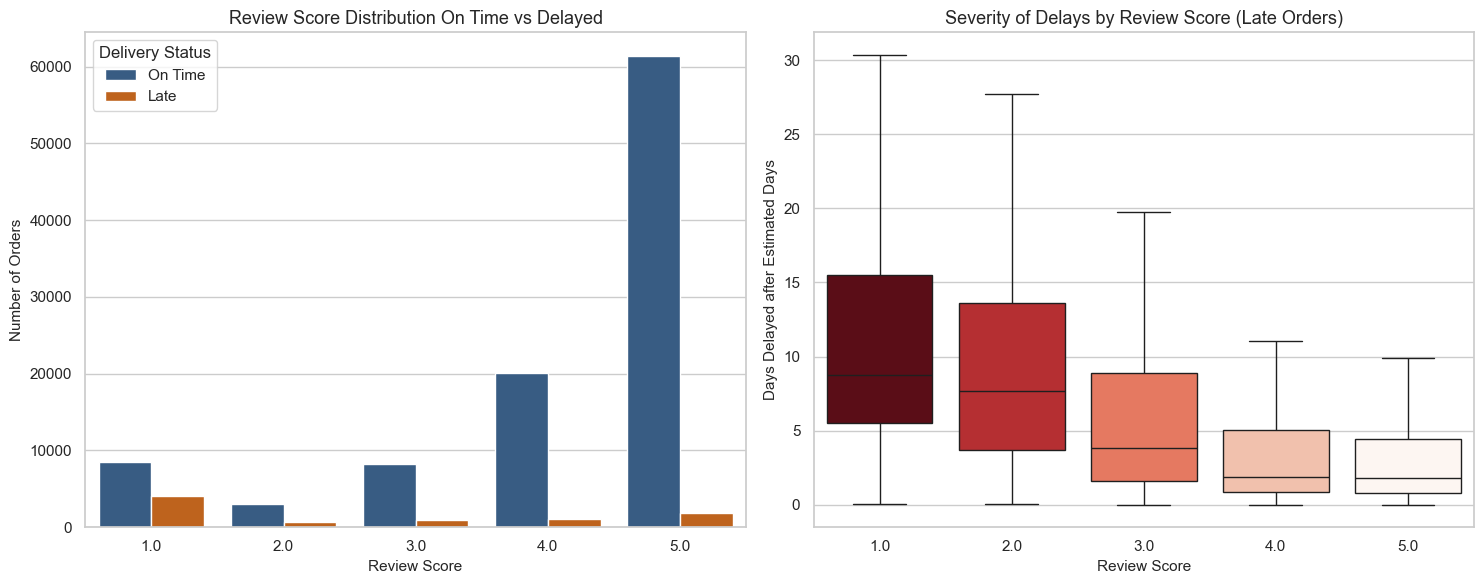

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
fig,axes = plt.subplots(1,2, figsize= (15,6))

#Plot 1 Review SCore Distribution

sns.countplot(
    data= review_df,
    x = 'review_score',
    hue='is_late',
    palette = ['#2b5c8f', '#d95f02'],
    ax = axes[0]
)
axes[0].set_title('Review Score Distribution On Time vs Delayed',fontsize=13)
axes[0].set_xlabel('Review Score', fontsize=11)
axes[0].set_ylabel('Number of Orders', fontsize=11)
axes[0].legend(title='Delivery Status', labels=['On Time','Late'])


# Plot 2 How does Delay Affect Rating
late_orders = review_df[review_df['delay_days']>0]

sns.boxplot(
    data= late_orders,
    x='review_score',
    hue='review_score',
    legend = False,
    y='delay_days',
    palette = 'Reds_r',
    ax= axes[1],
    showfliers = False
)
axes[1].set_title('Severity of Delays by Review Score (Late Orders)', fontsize=13)
axes[1].set_xlabel('Review Score', fontsize=11)
axes[1].set_ylabel('Days Delayed after Estimated Days',fontsize=11)

plt.tight_layout()
plt.show()

In [14]:
# Analysing State Wise Bottleneck


# This a top 10 States where  Orders are  Delivered Late
State_Group = review_df.groupby('customer_state').agg(
    Order_Volume = ('order_id','count'),
    Late_delivery_rate = ('is_late','mean'),
    Avg_delivery_days = ('delivery_days','mean'),
    Avg_review_score = ('review_score','mean')
).sort_values('Late_delivery_rate', ascending = False).head(10)
State_Group['Late_delivery_rate'] = (State_Group['Late_delivery_rate']*100).round(2)
print("------TOP 10 Late Delivery States-------")
print(State_Group)

    

------TOP 10 Late Delivery States-------
                Order_Volume  Late_delivery_rate  Avg_delivery_days  \
customer_state                                                        
AL                       428               23.60          24.402121   
MA                       799               19.77          21.437701   
SE                       373               15.82          21.322143   
PI                       519               15.41          19.413672   
CE                      1424               15.24          20.915049   
BA                      3669               13.44          19.187967   
RJ                     14051               12.81          15.092819   
TO                       309               12.30          17.464017   
ES                      2205               11.93          15.507663   
PA                      1041               11.34          23.505897   

                Avg_review_score  
customer_state                    
AL                      3.815421  
M

In [8]:
# Exporting to POWERBI
review_df.columns


Final_df = review_df[['order_id','customer_unique_id','customer_state','order_purchase_timestamp','order_delivered_customer_date', 'order_estimated_delivery_date','delivery_days','delay_days',
         'is_late','price','freight_value','review_score']].copy()
Final_df.dtypes
Final_df.to_csv('olist_delivery_analysis_final.csv', index = False)